In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('../build/training_stats.csv')

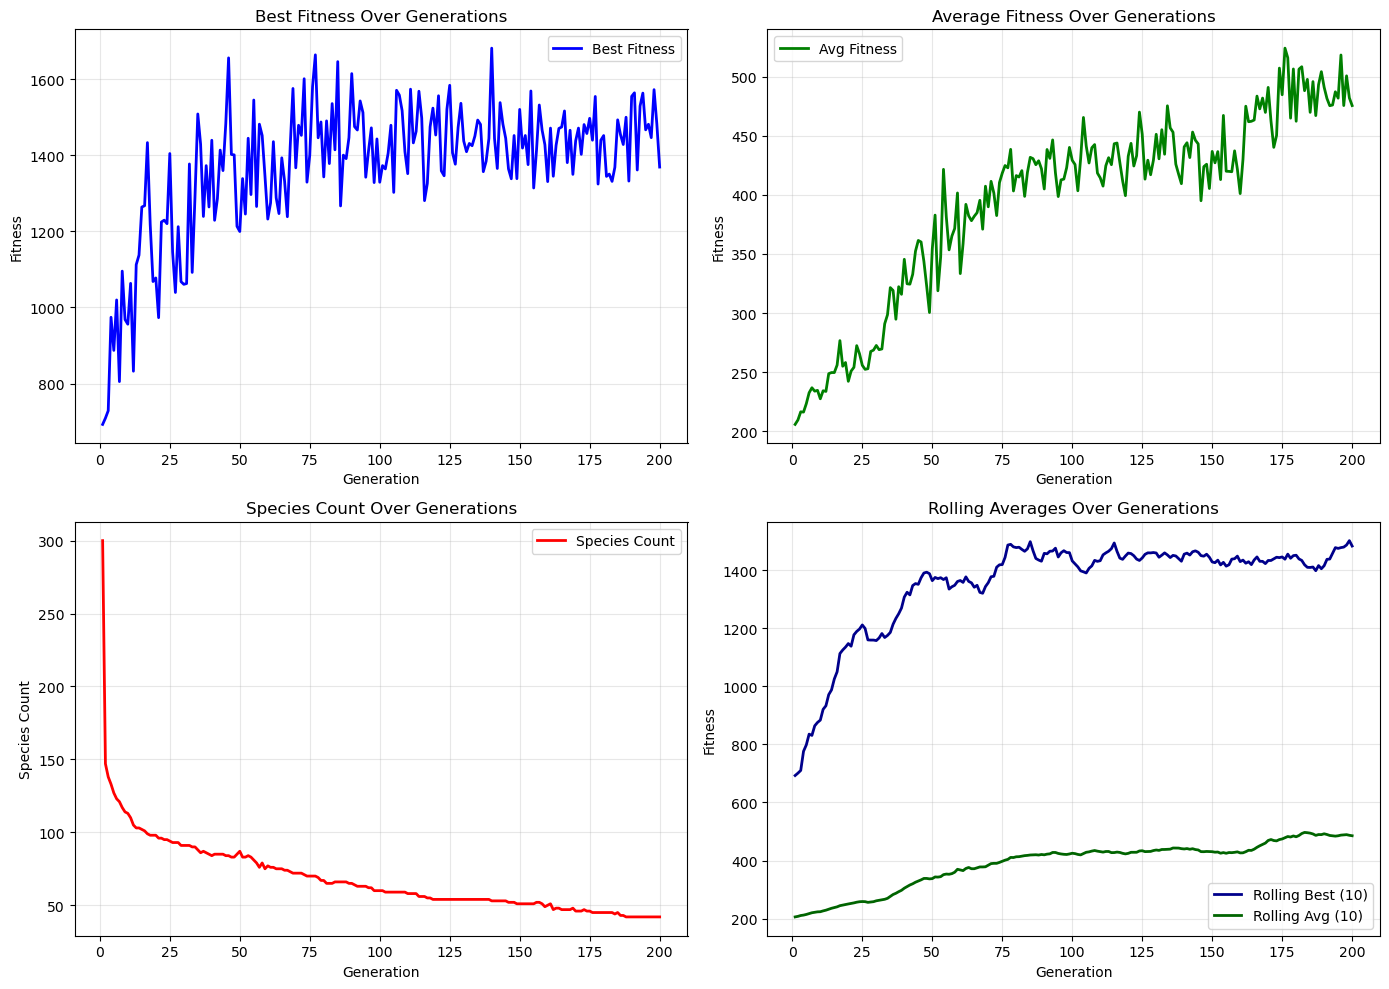

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(df['generation'], df['best_fitness'], label='Best Fitness', color='blue', linewidth=2)
axes[0, 0].set_xlabel('Generation')
axes[0, 0].set_ylabel('Fitness')
axes[0, 0].set_title('Best Fitness Over Generations')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend()

axes[0, 1].plot(df['generation'], df['avg_fitness'], label='Avg Fitness', color='green', linewidth=2)
axes[0, 1].set_xlabel('Generation')
axes[0, 1].set_ylabel('Fitness')
axes[0, 1].set_title('Average Fitness Over Generations')
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend()

axes[1, 0].plot(df['generation'], df['species_count'], label='Species Count', color='red', linewidth=2)
axes[1, 0].set_xlabel('Generation')
axes[1, 0].set_ylabel('Species Count')
axes[1, 0].set_title('Species Count Over Generations')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend()

axes[1, 1].plot(df['generation'], df['rolling_best_10'], label='Rolling Best (10)', color='darkblue', linewidth=2)
axes[1, 1].plot(df['generation'], df['rolling_avg_10'], label='Rolling Avg (10)', color='darkgreen', linewidth=2)
axes[1, 1].set_xlabel('Generation')
axes[1, 1].set_ylabel('Fitness')
axes[1, 1].set_title('Rolling Averages Over Generations')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

In [6]:
print("=" * 60)
print("TRAINING SUMMARY STATISTICS")
print("=" * 60)
print(f"\nTotal Generations: {len(df)}")
print(f"\nBest Fitness:")
print(f"  Start (Gen 1): {df['best_fitness'].iloc[0]:.2f}")
print(f"  End (Gen {len(df)}): {df['best_fitness'].iloc[-1]:.2f}")
print(f"  Peak: {df['best_fitness'].max():.2f} (Gen {df['best_fitness'].idxmax() + 1})")
print(f"  Improvement: +{df['best_fitness'].iloc[-1] - df['best_fitness'].iloc[0]:.2f} ({(df['best_fitness'].iloc[-1] / df['best_fitness'].iloc[0] - 1) * 100:.1f}%)")

print(f"\nAverage Fitness:")
print(f"  Start (Gen 1): {df['avg_fitness'].iloc[0]:.2f}")
print(f"  End (Gen {len(df)}): {df['avg_fitness'].iloc[-1]:.2f}")
print(f"  Improvement: +{df['avg_fitness'].iloc[-1] - df['avg_fitness'].iloc[0]:.2f} ({(df['avg_fitness'].iloc[-1] / df['avg_fitness'].iloc[0] - 1) * 100:.1f}%)")

print(f"\nSpecies Count (Diversity):")
print(f"  Start (Gen 1): {df['species_count'].iloc[0]}")
print(f"  End (Gen {len(df)}): {df['species_count'].iloc[-1]}")
print(f"  Change: -{df['species_count'].iloc[0] - df['species_count'].iloc[-1]} ({(1 - df['species_count'].iloc[-1] / df['species_count'].iloc[0]) * 100:.1f}% decrease)")

print(f"\nStdDev Fitness (Population Variance):")
print(f"  Start (Gen 1): {df['stddev_fitness'].iloc[0]:.2f}")
print(f"  End (Gen {len(df)}): {df['stddev_fitness'].iloc[-1]:.2f}")
print(f"  Average: {df['stddev_fitness'].mean():.2f}")

print(f"\nRolling Best (10 gens):")
print(f"  Start: {df['rolling_best_10'].iloc[9]:.2f}")
print(f"  End: {df['rolling_best_10'].iloc[-1]:.2f}")
print(f"  Improvement: {df['rolling_best_10'].iloc[-1] - df['rolling_best_10'].iloc[9]:.2f}")

print("\n" + "=" * 60)

TRAINING SUMMARY STATISTICS

Total Generations: 200

Best Fitness:
  Start (Gen 1): 692.87
  End (Gen 200): 1368.97
  Peak: 1681.33 (Gen 140)
  Improvement: +676.10 (97.6%)

Average Fitness:
  Start (Gen 1): 205.79
  End (Gen 200): 475.54
  Improvement: +269.74 (131.1%)

Species Count (Diversity):
  Start (Gen 1): 300
  End (Gen 200): 42
  Change: -258 (86.0% decrease)

StdDev Fitness (Population Variance):
  Start (Gen 1): 78.14
  End (Gen 200): 343.30
  Average: 301.87

Rolling Best (10 gens):
  Start: 883.80
  End: 1483.49
  Improvement: 599.69



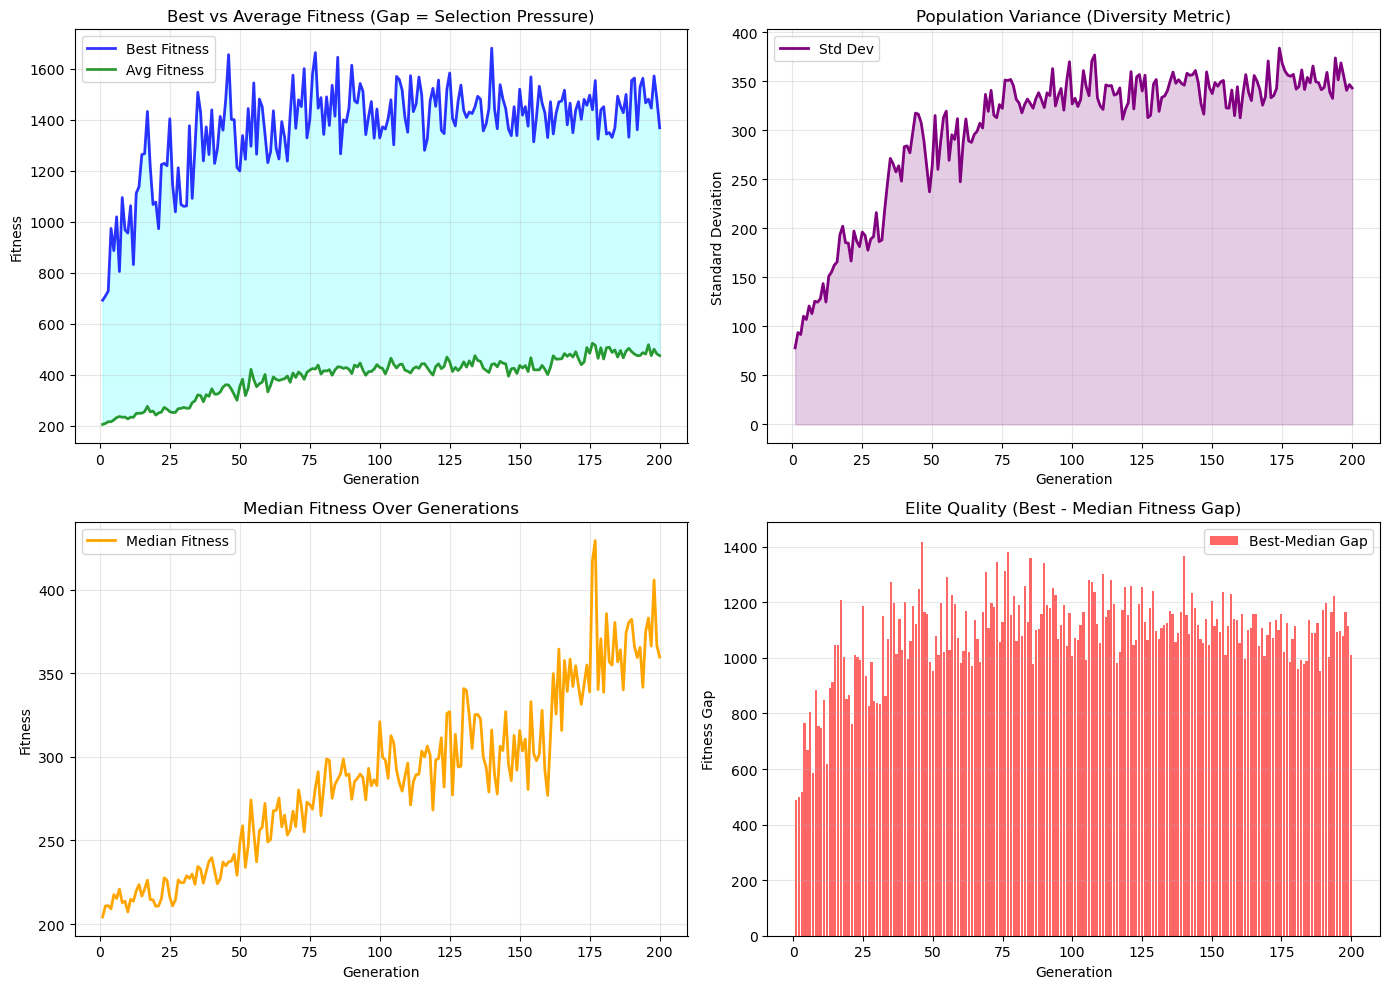

In [7]:
fig2, axes2 = plt.subplots(2, 2, figsize=(14, 10))

axes2[0, 0].plot(df['generation'], df['best_fitness'], label='Best Fitness', color='blue', linewidth=2, alpha=0.8)
axes2[0, 0].plot(df['generation'], df['avg_fitness'], label='Avg Fitness', color='green', linewidth=2, alpha=0.8)
axes2[0, 0].fill_between(df['generation'], df['avg_fitness'], df['best_fitness'], alpha=0.2, color='cyan')
axes2[0, 0].set_xlabel('Generation')
axes2[0, 0].set_ylabel('Fitness')
axes2[0, 0].set_title('Best vs Average Fitness (Gap = Selection Pressure)')
axes2[0, 0].grid(True, alpha=0.3)
axes2[0, 0].legend()

axes2[0, 1].plot(df['generation'], df['stddev_fitness'], label='Std Dev', color='purple', linewidth=2)
axes2[0, 1].set_xlabel('Generation')
axes2[0, 1].set_ylabel('Standard Deviation')
axes2[0, 1].set_title('Population Variance (Diversity Metric)')
axes2[0, 1].grid(True, alpha=0.3)
axes2[0, 1].legend()
axes2[0, 1].fill_between(df['generation'], 0, df['stddev_fitness'], alpha=0.2, color='purple')

axes2[1, 0].plot(df['generation'], df['median_fitness'], label='Median Fitness', color='orange', linewidth=2)
axes2[1, 0].set_xlabel('Generation')
axes2[1, 0].set_ylabel('Fitness')
axes2[1, 0].set_title('Median Fitness Over Generations')
axes2[1, 0].grid(True, alpha=0.3)
axes2[1, 0].legend()

gap = df['best_fitness'] - df['median_fitness']
axes2[1, 1].bar(df['generation'], gap, color='red', alpha=0.6, label='Best-Median Gap')
axes2[1, 1].set_xlabel('Generation')
axes2[1, 1].set_ylabel('Fitness Gap')
axes2[1, 1].set_title('Elite Quality (Best - Median Fitness Gap)')
axes2[1, 1].grid(True, alpha=0.3, axis='y')
axes2[1, 1].legend()

plt.tight_layout()
plt.show()

In [8]:
print("=" * 60)
print("LEARNING DYNAMICS ANALYSIS")
print("=" * 60)

seg_size = 50
segments = [df[df['generation'] <= i+seg_size]['best_fitness'].max() - df[df['generation'] <= i]['best_fitness'].min() 
            for i in range(seg_size, len(df) + seg_size, seg_size)]

print(f"\nBest Fitness Improvement by Period ({seg_size} gen intervals):")
for i, improvement in enumerate(segments[:-1]):
    gen_start = i * seg_size + 1
    gen_end = (i + 1) * seg_size
    print(f"  Gen {gen_start:3d}-{gen_end:3d}: +{improvement:7.2f}")

print(f"\nAverage Fitness by Period:")
for i in range(0, len(df), seg_size):
    end_idx = min(i + seg_size - 1, len(df) - 1)
    avg_val = df.iloc[i:end_idx]['avg_fitness'].mean()
    print(f"  Gen {i+1:3d}-{end_idx+1:3d}: {avg_val:7.2f}")

convergence_ratio = df['stddev_fitness'] / (df['best_fitness'] - df['avg_fitness'] + 1e-6)
print(f"\nConvergence Status (Stddev / Selection Pressure):")
print(f"  Early (Gen 1-20):   {convergence_ratio.iloc[0:20].mean():.3f}")
print(f"  Middle (Gen 80-100):{convergence_ratio.iloc[79:100].mean():.3f}")
print(f"  Late (Gen 180-200): {convergence_ratio.iloc[179:200].mean():.3f}")
print(f"  (Lower = better convergence)")

print("\n" + "=" * 60)
print("KEY OBSERVATIONS")
print("=" * 60)
print(f"✓ Best fitness grew by {(df['best_fitness'].iloc[-1] / df['best_fitness'].iloc[0]):.1f}x")
print(f"✓ Avg fitness grew {(df['avg_fitness'].iloc[-1] / df['avg_fitness'].iloc[0]):.1f}x")
print(f"✓ Species collapsed from {df['species_count'].iloc[0]} to {df['species_count'].iloc[-1]} (speciation working)")
print(f"✓ Population variance stabilized around {df['stddev_fitness'].iloc[100:].mean():.0f}")
print(f"✓ Elite-median gap is {gap.iloc[-1]:.0f} (stronger elites in later gens)")
print("=" * 60)

LEARNING DYNAMICS ANALYSIS

Best Fitness Improvement by Period (50 gen intervals):
  Gen   1- 50: + 970.85
  Gen  51-100: + 988.46
  Gen 101-150: + 988.46

Average Fitness by Period:
  Gen   1- 50:  273.95
  Gen  51-100:  401.38
  Gen 101-150:  432.35
  Gen 151-200:  470.88

Convergence Status (Stddev / Selection Pressure):
  Early (Gen 1-20):   0.178
  Middle (Gen 80-100):0.331
  Late (Gen 180-200): 0.367
  (Lower = better convergence)

KEY OBSERVATIONS
✓ Best fitness grew by 2.0x
✓ Avg fitness grew 2.3x
✓ Species collapsed from 300 to 42 (speciation working)
✓ Population variance stabilized around 344
✓ Elite-median gap is 1009 (stronger elites in later gens)


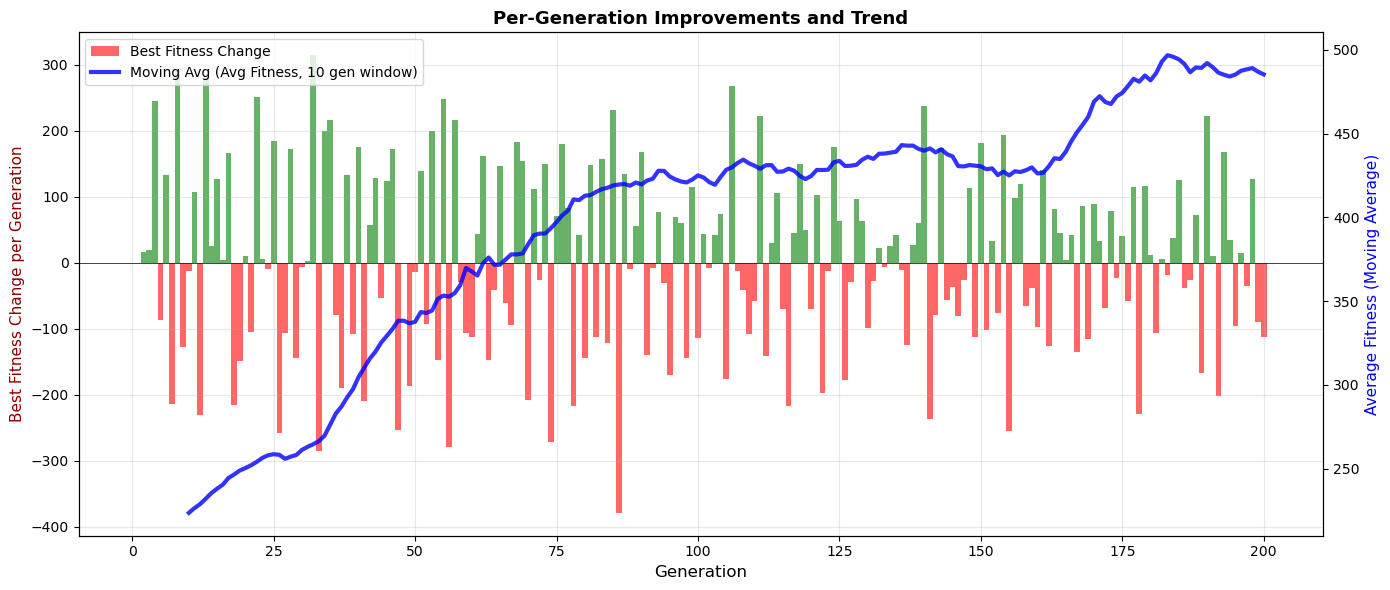


Best Improvement Stats:
  Positive changes: 102 generations
  Negative changes: 97 generations
  Max single jump: +314.20
  Larger improvements (>100): 54 times


In [9]:
fig3, ax = plt.subplots(figsize=(14, 6))

best_improvement = df['best_fitness'].diff().fillna(0)
avg_improvement = df['avg_fitness'].diff().fillna(0)

ax1 = ax
ax2 = ax1.twinx()

colors = ['green' if x > 0 else 'red' for x in best_improvement]
ax1.bar(df['generation'], best_improvement, label='Best Fitness Change', alpha=0.6, color=colors, width=1)

window = 10
moving_avg = df['avg_fitness'].rolling(window=window).mean()
ax2.plot(df['generation'], moving_avg, label=f'Moving Avg (Avg Fitness, {window} gen window)', 
         color='blue', linewidth=3, alpha=0.8)

ax1.set_xlabel('Generation', fontsize=12)
ax1.set_ylabel('Best Fitness Change per Generation', fontsize=11, color='darkred')
ax2.set_ylabel('Average Fitness (Moving Average)', fontsize=11, color='blue')
ax1.set_title('Per-Generation Improvements and Trend', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.axhline(y=0, color='black', linestyle='-', linewidth=0.5)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()

print(f"\nBest Improvement Stats:")
print(f"  Positive changes: {(best_improvement > 0).sum()} generations")
print(f"  Negative changes: {(best_improvement < 0).sum()} generations")
print(f"  Max single jump: +{best_improvement.max():.2f}")
print(f"  Larger improvements (>100): {(best_improvement > 100).sum()} times")